In [1]:
# Enable auto-reloading so edits to .py files update without restarting the kernel
%load_ext autoreload
%autoreload 2

import numpy as np
import complex_network_dynamics as cnd
import matplotlib.pyplot as plt
import pandas as pd 
import time

### Calling Network Data From the package

(16, 16)


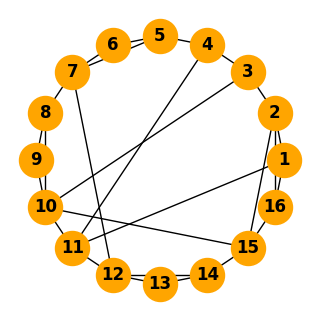

In [2]:
import networkx as nx

# Load the matrix directly
adj_16nodes = cnd.load_network("16nodes")
print(adj_16nodes.shape)
G = nx.from_numpy_array(adj_16nodes)
# Visualize the graph
plt.figure(figsize=(3, 3))
pos = nx.circular_layout(G)
custom_labels = {node: node + 1 for node in G.nodes()}
nx.draw(
    G, 
    pos, 
    with_labels=True,
    labels=custom_labels, 
    node_color="orange", 
    node_size=600, 
    edge_color="black", 
    font_weight="bold"
)
# plt.title(f"Random {d}-Regular Graph with {n} Nodes")
plt.show()

### Data Simulation: Coupled Logistic Map

In [3]:
M = adj_16nodes.shape[0] #number of nodes M
x0 = np.random.rand(M) 
t=int(1e5)
n_transient = int(2e4)

traj, lyap_exp = cnd.discrete_models.simulate_discrete_models(
    x0,
    f = cnd.logistic,
    df = cnd.df_logistic,
    A = adj_16nodes,
    t=t,
    alpha=0.1,
    n_transient=n_transient,
   r = 4,  # fully chaos in logistic
)

In [4]:
max(lyap_exp)  # positive Lyapunov indicates the chaotic behaviour

0.44849105758697305

### Pearson Correlation of Pairs

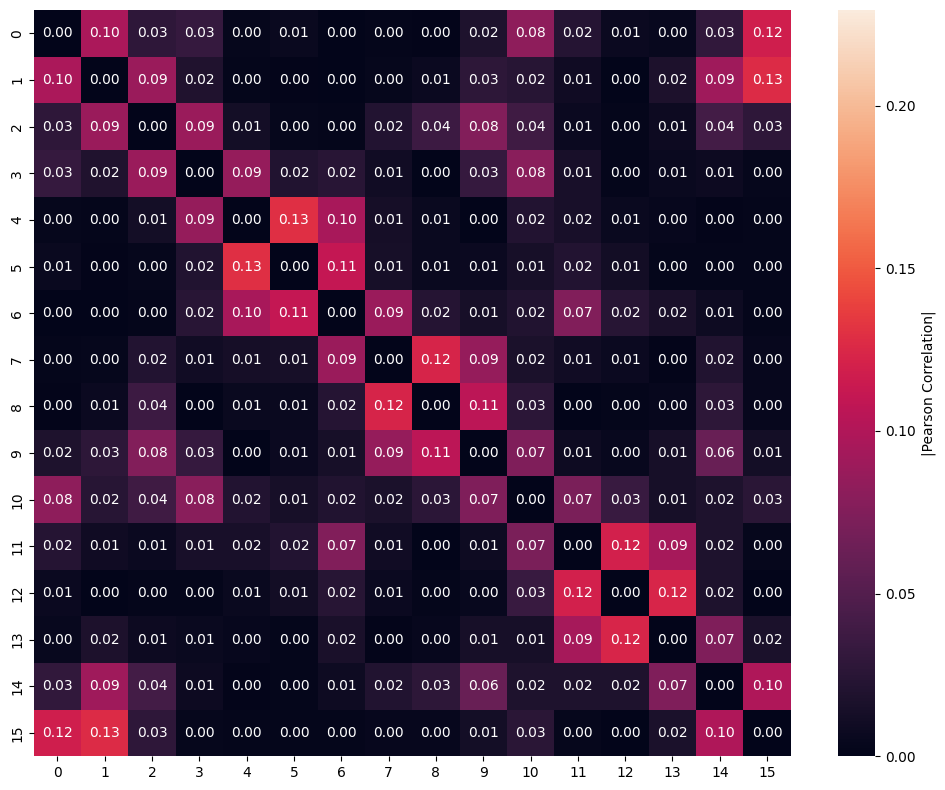

In [5]:
import seaborn as sns

pc_matrix = np.corrcoef(traj, rowvar=False)
abs_pc_matrix = np.abs(pc_matrix)
np.fill_diagonal(abs_pc_matrix, 0)

plt.figure(figsize=(10, 8))
ax = sns.heatmap(
    abs_pc_matrix,
    annot=True,
    fmt=".2f",
   #cmap=cmap,
    vmin=0.0,
    vmax=np.max(abs_pc_matrix)+0.1,
    # xticklabels=node_labels,
    # yticklabels=node_labels,
    cbar_kws={"label": "|Pearson Correlation|"},
)

plt.tight_layout()
plt.show()

### Network Inference using Pearson Correlation

The function `plot_similarity_gap_bar` from the `network_inference` at the Python library `Complex Network Dynamics`, shows the given - as an input- similarity measure and compare the values with original network (ground-truth). It gives a bar plot -sorted values or unsorted-, red bars indicating unconnected pairs whereas the greens connected ones. The grey band is the optimal threshold values to infer 100% correct network topology. 

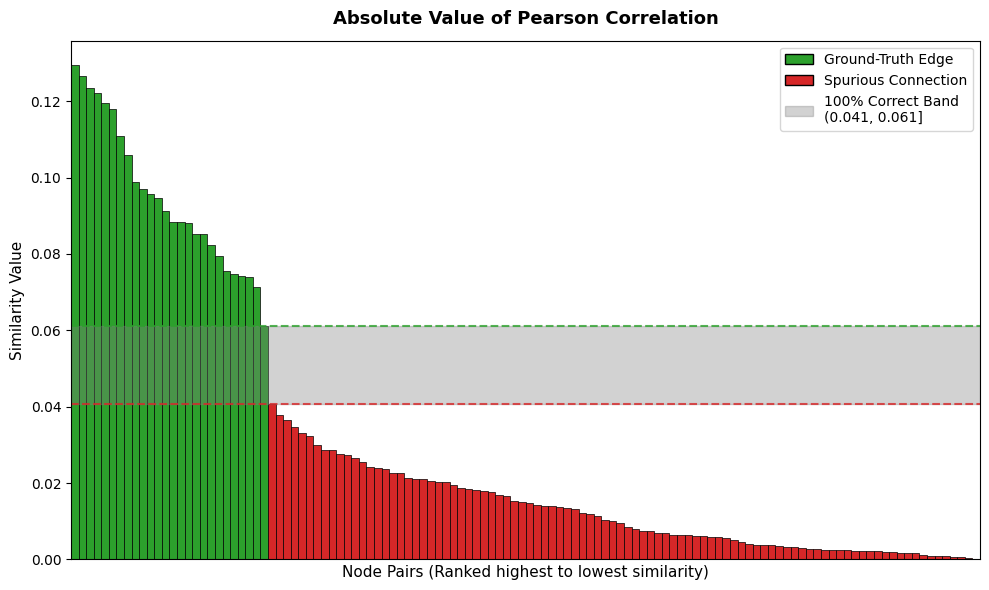

(0.04076505579079108, 0.0611835922430371)

In [12]:
cnd.network_inference.plot_similarity_gap_bars(abs_pc_matrix, adj_16nodes, sort_bars=True, title="Absolute Value of Pearson Correlation")

<div> <h3> Mutual Information </h3>


Explanation about mutual information and how to compute it...  

</div>

In [26]:
cnd.network_inference.Grid(traj) # Grid size based on the eq.17 in the paper "successful network inference . . . "  It finds the range of gridsize values. 

(3, 17)

In [13]:
Mir, Mi = cnd.network_inference.MIR(traj, N_range = None, nodes=None)

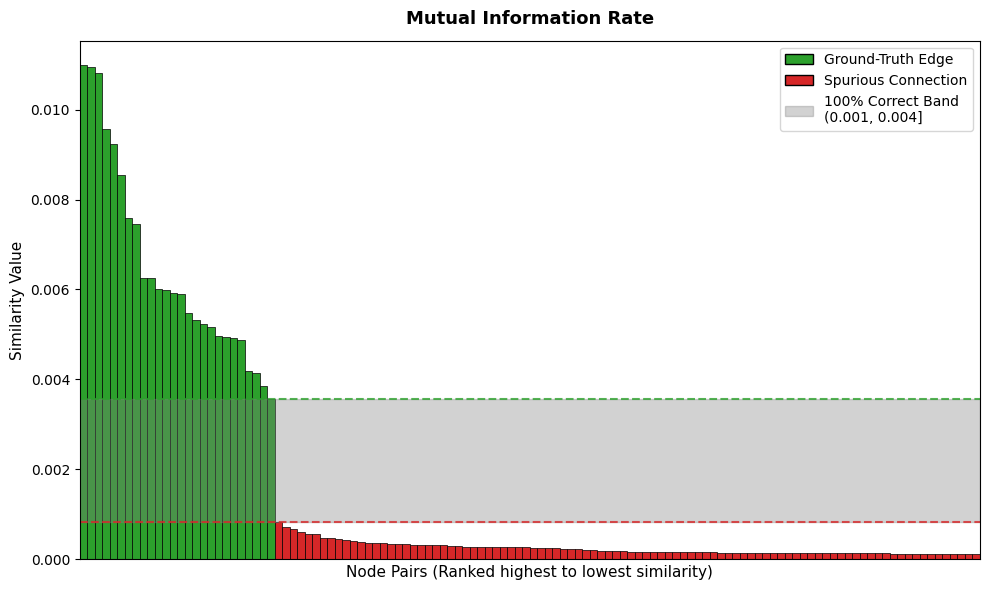

(0.0008319803226960806, 0.0035605445960572037)

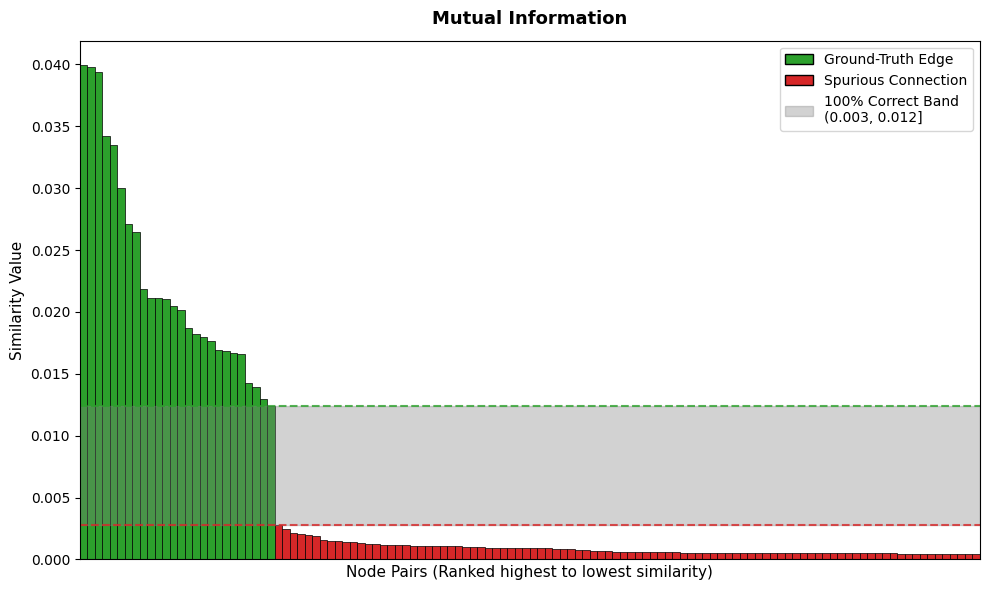

(0.0028049276572153633, 0.012392139702043937)

In [17]:
cnd.network_inference.plot_similarity_gap_bars(Mi, adj_16nodes, sort_bars=True, title = "Mutual Information")

## Correlation Decay Time 

In [21]:
cnd.network_inference.corr_decay(traj, 17)

array([[0., 5., 4., 4., 4., 4., 4., 4., 4., 4., 5., 4., 4., 4., 4., 5.],
       [5., 0., 5., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 5., 5.],
       [4., 5., 0., 5., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4.],
       [4., 4., 5., 0., 4., 4., 4., 4., 4., 4., 5., 4., 4., 4., 4., 4.],
       [4., 4., 4., 4., 0., 5., 5., 4., 4., 4., 4., 4., 4., 4., 4., 4.],
       [4., 4., 4., 4., 5., 0., 5., 4., 4., 4., 4., 4., 4., 4., 4., 4.],
       [4., 4., 4., 4., 5., 5., 0., 5., 4., 4., 4., 4., 4., 4., 4., 4.],
       [4., 4., 4., 4., 4., 4., 5., 0., 5., 4., 4., 4., 4., 4., 4., 4.],
       [4., 4., 4., 4., 4., 4., 4., 5., 0., 5., 4., 4., 4., 4., 4., 4.],
       [4., 4., 4., 4., 4., 4., 4., 4., 5., 0., 4., 4., 4., 4., 5., 4.],
       [5., 4., 4., 5., 4., 4., 4., 4., 4., 4., 0., 5., 4., 4., 5., 4.],
       [4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 5., 0., 5., 5., 4., 4.],
       [4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 5., 0., 5., 4., 4.],
       [4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4.,

## Mutual Information Rate

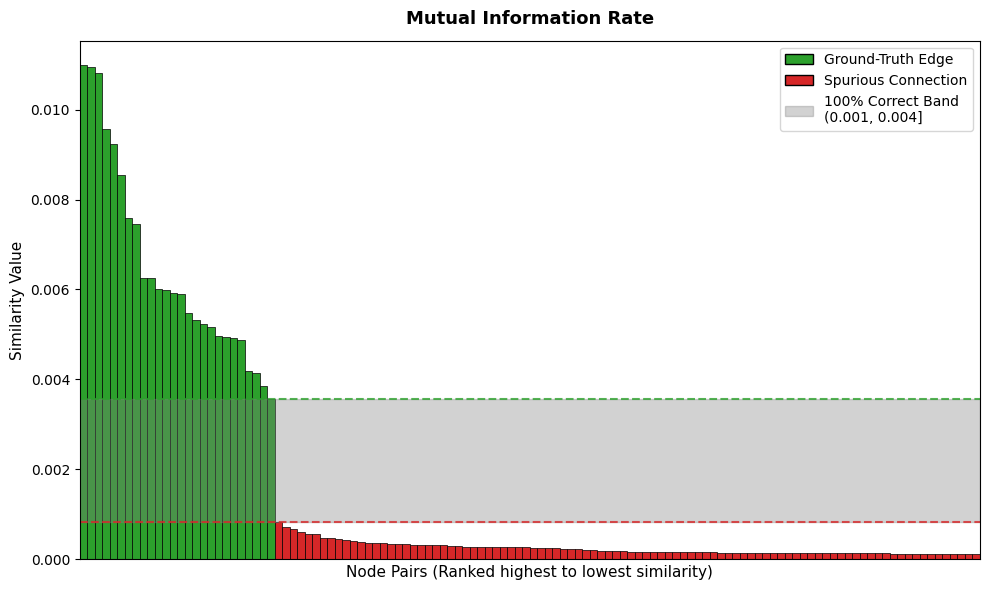

(0.0008319803226960806, 0.0035605445960572037)

In [27]:
cnd.network_inference.plot_similarity_gap_bars(Mir, adj_16nodes, sort_bars=True, title = "Mutual Information Rate")